<a href="https://colab.research.google.com/github/ERone1207/TCSRone/blob/main/EVAN_SPOTIFY_FINAL_(for_submission)_Project_TCS_2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Drop the Beat, Not the Data: How My ML Model Became a Spotify DJ**

## The Coding School 2025

### **Evan Rone**

---



## Spotify 2023 Machine Learning Project

**Topic Overview:** *(from the Coding School Doc)*

What was the most popular song of 2023? Large streaming platforms like Spotify keep detailed datasets of their users’ listening habits, because this data can be analyzed to uncover patterns in what makes music enjoyable to different people., These patterns are important to Spotify as they train “recommendation engines”, algorithms which predict which new songs a particular user will like. This project will introduce students to the process a streaming platform would go through to discover patterns in a large, real-world music dataset filled with many quantitative features about each song.

**Dataset Description:**

This dataset contains a total of 947 different songs that were the most popular on Spotify in 2023. A total of 24 features are included for each song, including the track and artist(s) names, as well as numerous measurements ranging from the number of Spotify playlists the song was included on to the beats per minute, key and mode of the song. Each row represents an individual song.


I'm using the publicly available Spotify dataset from 2023 to explore how machine learning can predict which features of a song are closely linked to its popularity. With 24 different features to analyze, I want to see which ones really impact the number of streams (a measure of how often a song is played).

By identifying the most closely related key features instrinsic to the song, artists' could find out what elements can help them reach a larger audience using predictive modeling.

## **ABSTRACT**

***This project explored what makes a song popular based on how often it is streamed. The most important features found were whether the song appeared on Spotify or Apple playlists or charts, and what year it was released. We looked at whether songs released in certain months, like November and December, were streamed more, but found no strong connection. Only June and July had slightly higher average streams. We also checked if features like energy, BPM, or liveliness changed during the holiday season, but found no big differences. The Release Year helped predict popularity a little, but not enough on its own to make accurate predictions. In the end, the hypothesis that music is streamed more during the holiday season was proven false.***

---

## **Research Questions (Problem):**

So, my initial question is: ***what are the top three features in a song that predict its popularity ("streams" in Spotify), and presence on both Spotify and Apple Music playlists?*** Then, using the single most predictive feature identified does this feature help predict popularity (again based on the number of Spotify streams) to the same degree if the 2024 Spotify data is also used?*

Additionally, I think songs tend to be more popular during the holiday season in November and December, when families are often together. While this question may be answered from looking at the top features that correlate with streams I would like to look at this metric separately as well.

## **Hypothesis:**

Because of family gatherings and social events, more music will likely be streamed during the holiday months of November and December. If one to three important features of a song (like how BPM, energy, liveness) can predict song popularity using 2023 Spotify data, then those same features should also help predict popular songs in the 2024 Spotify data.


---
### **Approach**

*Setting out to address my hypothesis in a step-wise fashion by addressing these smaller questions which will help answer the hypothesis.*

1.) Define which key features are most predictive of song popularity as identified by streams?

2.) Identify the seasonal or monthly patterns in streamed songs. Focusing on November-December months do certain songs have increased energy, liveness, BPM?

3.) Using the single most (intrinsic) predictive feature identified does this feature help predict popularity to the same degree if the 2024 Spotify data is also used?



## **METHODOLOGY**

*Using the 2023 and 2024 Spotify Datasets with 24 features, I grouped the data primarily by intrinsic and extrinsic variables for analysis. I used correlation matricies and correlation efficients to define variables closest to the feature I was focused on, "streams." *

1.   Import the necessary basic libraries (Matplotlib, Pandas, Numpy, Seaborn, Skit-Learn, Warnings)
2.   Import 2023 Spotify Data from the provided link: https://www.kaggle.com/datasets/nelgiriyewithana/top-spotify-songs-2023
3.   Explored the 2023 datasets (Namely features, data types and identifying null values)
4.   Identified relationships between features using Correlation Matrix, Heat Maps and looking at correlation coefficients
5.   Grouped unique features by release month
6.   Uploaded the 2024 dataset and Repeat (Data Analysis and Cleaning Steps)
7.  Using the single most predictive value related to streaming in the 2023 dataset create and test a model to see if it is similarly predictive for 2024


In [1]:
!pip install matplotlib
import matplotlib.pyplot as plt
# Library in Python for creating static, animated, and interactive visualizations

!pip install pandas
import pandas as pd
# Open source library for data manipulation

!pip install numpy
import numpy as np
# Numerical library in python for scientific data

!pip install seaborn
import seaborn as sns
# open-source Python library for creating informative and aesthetically pleasing statistical graphics

!pip install scikit-learn
from sklearn import datasets, model_selection
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.datasets import make_regression
# Free open source library for machine learning

import warnings
warnings.filterwarnings('ignore')

In [2]:
#Create Dataframe

# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "spotify-2023.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "nelgiriyewithana/top-spotify-songs-2023",
  file_path, pandas_kwargs={'encoding': 'latin-1'})

100%|██████████| 104k/104k [00:00<00:00, 244kB/s]


*Importing the Feature Key with defined terms directly from the Spotify 2023 Dataset*

**Feature Key**

*  track_name: Name of the song
*  artist(s)_name: Name of the artist(s) of the song
*  artist_count: Number of artists contributing to the song
*  released_year: Year when the song was released
*  released_month: Month when the song was released
*  released_day: Day of the month when the song was released
*  in_spotify_playlists: Number of Spotify playlists the song is included in
*  in_spotify_charts: Presence and rank of the song on Spotify charts
*  streams: Total number of streams on Spotify
*  in_apple_playlists: Number of Apple Music playlists the song is included in
*  in_apple_charts: Presence and rank of the song on Apple Music charts
*  in_deezer_playlists: Number of Deezer playlists the song is included in
*  in_deezer_charts: Presence and rank of the song on Deezer charts
*  in_shazam_charts: Presence and rank of the song on Shazam charts
*  bpm: Beats per minute, a measure of song tempo
*  key: Key of the song
*  mode: Mode of the song (major or minor) - *Major modes are often perceived as sounding bright and happy, while minor modes are associated with a more somber or melancholic feeling*
*  danceability_%: Percentage indicating how suitable the song is for dancing
*  valence_%: Positivity of the song's musical content
*  energy_%: Perceived energy level of the song
*  acousticness_%: Amount of acoustic sound in the song
*  instrumentalness_%: Amount of instrumental content in the song
*  liveness_%: Presence of live performance elements
*  speechiness_%: Amount of spoken words in the song

#### **DATA ANALYTICS and EXPLORATION**


In [38]:
# Major and minor values represent MAJOR - Bright/Happy or MINOR - "SOMBER/MELANCHOLY"
# Had to change categorical data into numerical data to use in graphs/charts
# Created a dictionary using braces and named the dictionary "numerical_mode"
# Dictionary will replace the identified words - Major/Minor with 1 or 0 (Key-value pairs)
numerical_mode = {"Major": 1, "Minor": 0}

# Use the .map and it will tell pandas to go in the ["mode"] column within the df = df["mode"] and replace each instance of major or minor with the dictionary "numerical_mode"
df["mode"] = df["mode"].map(numerical_mode)

# Count the number of songs in each mode
mode_counts = df['mode'].value_counts()

# 1 = Major or happy songs
# 2 = Minor or sad songs

In [39]:
# Get the value counts of 'released_year' and sort by index (year)
# An index is the main value being defined/searched by, in this case each year (ROW) in the ["released_year"] column
# Instead of ".sort_values()" which would be a function (or dependent on) of value counts
# Sorting by ".sort_index()" instead will sort based on the index, in this case ["released_year"]

released_year_ordered = df['released_year'].value_counts().sort_index()

# Display the sorted counts

#### **DATA CLEANING**

In [11]:
# When initially loaded the ["streams"] column was listed as data type: OBJECT
# It was an OBJECT (usually a STRING = mixed data) likely because of the commas separating the numbers 1,000,000
# To use this data in charts, analysis it should be converted to ONLY NUMBERS (Integers or Floats)

# STEP 1.) Convert the 'streams' column to numeric, coercing errors to NaN
# errors='coerce' replaces ANY values it cannot change into numbers into NaN (not a number)
# The NaN represents missing data instead of just returning an error message

# pd.to_numeric() is a PANDAS FUNCTION that converts the identified column (SERIES) into a number data type
# the df["streams"] = looks at this conversion and rewrites that entire column according to the instructions (code)

df['streams'] = pd.to_numeric(df['streams'], errors='coerce')

# Check the data type of the 'streams' column to confirm the conversion
print("New Data Type AFTER the 'streams' column conversion:", df['streams'].dtype)

# Check for any values that were coerced to NaN
print("\nNumber of NaN values in 'streams' column after conversion:", df['streams'].isnull().sum())

# REMINDER: the \n just starts a new line for ease of reading

New Data Type AFTER the 'streams' column conversion: float64

Number of NaN values in 'streams' column after conversion: 1


In [13]:
# CURIOUS - what OBJECT value was in the original "stream" value for the now NaN value
# Index 574
# Load the dataset again without converting the 'streams' column
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "spotify-2023.csv"

df_original = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "nelgiriyewithana/top-spotify-songs-2023",
  file_path,
  pandas_kwargs={'encoding': 'latin-1'})

# Created a second dataframe = df_original, recall the actual first dataframe used is just called "df"
# Creating this second dataframe will make sure the other changes from data clean-up aren't disturbed

# The .loc[...] allows LOCATION-BASED finding or indexing in Pandas. In other words, you can find a particular cell if you think of a df like a spreadsheet
# .loc[ROW #, "Column_Name"] in this case = new_df.loc[574, 'streams']
# Display the original value in the 'streams' column for the row at index 574

print("Original entry in 'streams' column for row 574:")
print(df_original.loc[574, 'streams'])

# Seems the original Spotify list 2023 was uploaded with an error in that cell - since it's used for training it's likely intentional but it also is nonsense with multiple fields merged


Original entry in 'streams' column for row 574:
BPM110KeyAModeMajorDanceability53Valence75Energy69Acousticness7Instrumentalness0Liveness17Speechiness3


## **RESULTS:**

Looking to see how each feature relates to the other features (metrics) so we can select the most closely related features to predict popularity ("streams") of a song.


*   Create or Correlation Matrix - looks to see numerical relationships (positive and negative correlations)
*   Per google, Heat Maps are a nice way to visualize a correlation matrix



In [84]:
# Here's a quick interpretation:

# Positive correlation (warm colors, closer to 1): As one feature increases, the other also tends to increase.
# Negative correlation (cool colors, closer to -1): As one feature increases, the other tends to decrease.
# Weak correlation (colors closer to 0): Little to no linear relationship between the features.

#Looking at the heatmap, you can identify which features have strong correlations. For example, 'in_spotify_playlists' shows a relatively strong positive correlation with 'in_apple_playlists', which makes sense. 'energy_%' and 'acousticness_%' show a strong negative correlation, which is also expected as acoustic songs tend to have less perceived energy.

# Select only numerical columns
numerical_df = df.select_dtypes(include=np.number)

# numerical_df is creating a new dataframe composed of what is requested, in this cases all numerical dtypes
# df.select_dtpes(...) is a PANDAS function that allows selection of specific data types from within the dataframe
# (include=np.number) means to keep (include) np.number which includes Integers (int64) and Floats (floats64) from the NumPy library imported initially

# Create the correlation matrix built on ONLY numeric data from the new numerical dataframe next
correlation_matrix = numerical_df.corr()

# Display the correlation matrix
print("FIGURE 1 - Correlation Coefficients of Features:")
display(correlation_matrix)



FIGURE 1 - Correlation Coefficients of Features:


,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,in_deezer_charts,...,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%,release_month_only,released_month_only
artist_count,1.000000,0.070900,0.032788,-0.015870,-0.085454,-0.009075,-0.109760,-0.017501,-0.076131,0.020231,...,NaN,0.213480,0.124561,0.137801,-0.095365,-0.061438,0.034294,0.130978,0.032788,0.032788
released_year,0.070900,1.000000,0.069671,0.161053,-0.397052,0.066054,-0.242726,-0.207317,-0.002027,0.094426,...,NaN,0.212401,-0.042665,0.081478,-0.139154,-0.025322,0.008115,0.127461,0.069671,0.069671
released_month,0.032788,0.069671,1.000000,0.055562,-0.123000,-0.051346,-0.046041,-0.035094,-0.019569,0.006168,...,NaN,-0.056599,-0.108818,-0.086510,0.053824,0.035195,0.001182,0.040921,1.000000,1.000000
released_day,-0.015870,0.161053,0.055562,1.000000,-0.108171,0.015034,-0.025116,-0.012921,0.006065,0.054735,...,NaN,0.082746,0.064553,0.047858,-0.000485,0.022746,-0.011252,-0.015859,0.055562,0.055562
in_spotify_playlists,-0.085454,-0.397052,-0.123000,-0.108171,1.000000,0.141186,0.780404,0.688306,0.215504,0.101158,...,NaN,-0.097348,-0.029527,0.035968,-0.064896,-0.024631,-0.052002,-0.077870,-0.123000,-0.123000
in_spotify_charts,-0.009075,0.066054,-0.051346,0.015034,0.141186,1.000000,0.214034,0.207841,0.556509,0.566020,...,NaN,0.050623,0.050862,0.105217,-0.073482,-0.005963,-0.026655,-0.094726,-0.051346,-0.051346
streams,-0.109760,-0.242726,-0.046041,-0.025116,0.780404,0.214034,1.000000,0.735321,0.269137,0.184329,...,NaN,-0.093268,-0.051014,-0.036499,-0.005751,-0.033039,-0.056664,-0.099968,-0.046041,-0.046041
in_apple_playlists,-0.017501,-0.207317,-0.035094,-0.012921,0.688306,0.207841,0.735321,1.000000,0.364339,0.326598,...,NaN,-0.013306,0.042017,0.040211,-0.071554,-0.054524,-0.065062,-0.098233,-0.035094,-0.035094
in_apple_charts,-0.076131,-0.002027,-0.019569,0.006065,0.215504,0.556509,0.269137,0.364339,1.000000,0.366295,...,NaN,-0.027371,0.044229,0.129793,-0.097803,-0.000615,-0.007271,-0.147513,-0.019569,-0.019569
in_deezer_charts,0.020231,0.094426,0.006168,0.054735,0.101158,0.566020,0.184329,0.326598,0.366295,1.000000,...,NaN,0.080926,0.073786,0.104529,-0.035575,0.003396,0.003602,-0.081971,0.006168,0.006168


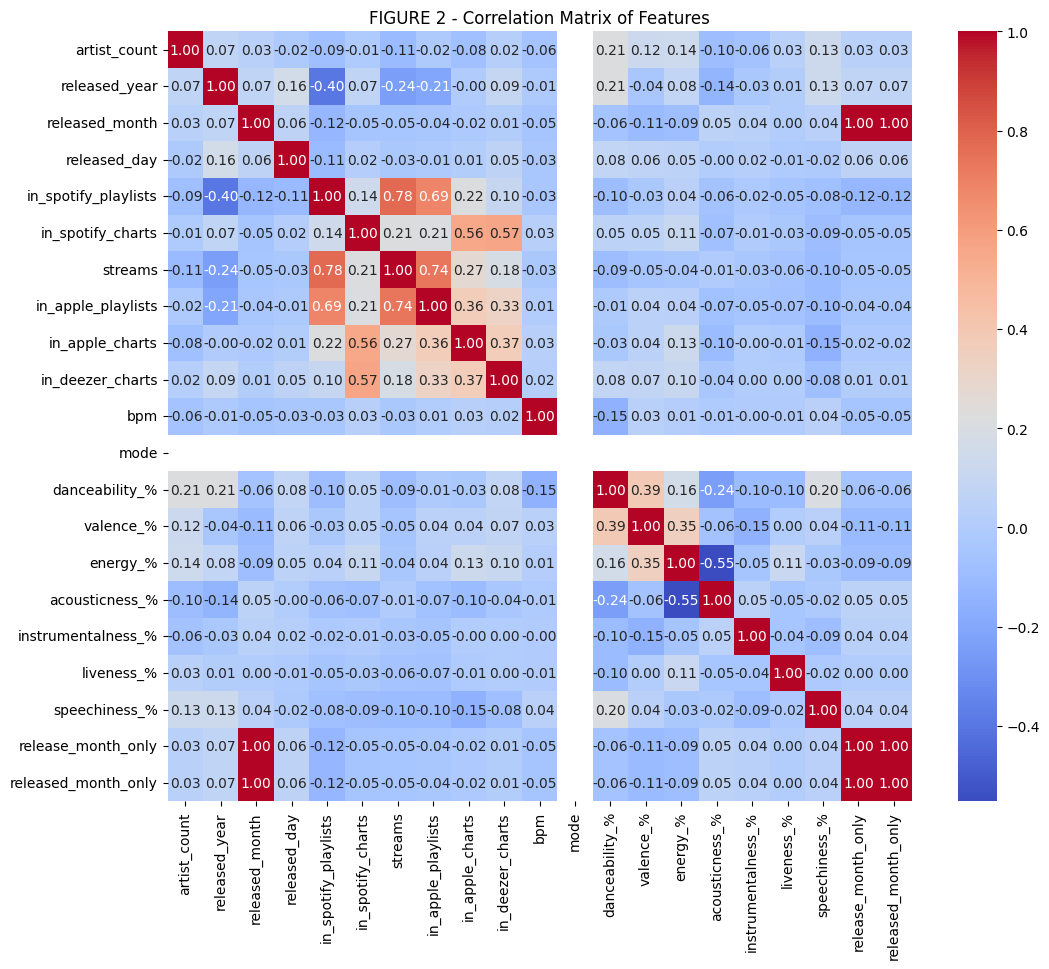

In [85]:
# Visualize the correlation matrix also using a heatmap
# plt.figure() creates a blank HTML like canvas and you tell it what size canvas, figsize=(12,10) width x height
# sns.heatmap() is the function to create the heatmap, (correlation_matrix is the new numerical correlation matrix df created above)
# (correlation_matrix, annot=True this means write annotated or abbreviated 2 decimal in this case, value in each cell instead of just using colors)
# cmap= 'coolwarm' per google is a common choice in colors for the heatmap
# fmt=".2f" means formating the floating numbers two decimal places
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('FIGURE 2 - Correlation Matrix of Features')
plt.show()

In [16]:
# Get the correlations of 'streams' with all other features
# Creating a new focus streams_correlations =
# look in the correlation_matrix dataframe in the ["streams"] column then
# FIRST sort the data by absolute value so that the positive and negative correlating values are in the correct relevant order THEN sort the values in ORDER from HIGH to LOW.
# Ascending=False means High to low if True values would have shown Low to High

streams_correlations = correlation_matrix['streams'].abs().sort_values(ascending=False)

# Exclude the correlation of 'streams' with itself - obviously, 'streams' would have a value of 1 with itself
streams_correlations = streams_correlations.drop('streams')

# Get the top 10 features most correlated with streams
top_10_streams_correlations = streams_correlations.head(10)

print("Top 10 features most closely related to 'streams':")
print(top_10_streams_correlations)

# Instead of dropping various features I can just include more in what is shown in the correct order and exclude features I am not interested in

Top 10 features most closely related to 'streams':
in_spotify_playlists    0.789822
in_apple_playlists      0.772063
in_apple_charts         0.320234
in_spotify_charts       0.245821
released_year           0.230803
in_deezer_charts        0.228598
artist_count            0.136463
speechiness_%           0.112333
danceability_%          0.105457
liveness_%              0.048337
Name: streams, dtype: float64


### **OBJECTIVE ONE:**
#### Define which key features are most predictive of song popularity as identified by streams?


Select the top 10 most correlated features from the `streams_correlations` Series as predictor variables (X) and 'streams' as the target variable (y).


Based on the Correlation Maps, song popularity, as identified by correspondence to "Streams" is most closely related to:


*   Frequency in the number of individual Spotify and Apple Playlists the song is featured in
*   The songs placement in the Apple and Spotify Charts
*   Release year of the song


Intrinisic to the song itself top predictive factors of popularity (streaming) is based on:

*   Release year of the song
*   The number of performing artists in the song
*   Speechiness
*   Danceability

In [17]:
# Get the correlations of 'streams' with all other features (absolute values, sorted ascending)
# It is the same code renamed and simply in ascending order from LEAST to GREATEST

streams_correlations_weakest = correlation_matrix['streams'].abs().sort_values(ascending=True)

# Exclude the correlation of 'streams' with itself
streams_correlations_weakest = streams_correlations_weakest.drop('streams')

# Get the top 5 features least correlated with streams
top_5_unrelated_streams = streams_correlations_weakest.head(5)

print("Top 5 features least related to 'streams':")
print(top_5_unrelated_streams)

Top 5 features least related to 'streams':
bpm               0.002438
acousticness_%    0.004485
released_day      0.010598
released_month    0.024938
energy_%          0.026051
Name: streams, dtype: float64


Surprisingly, based on the correlation mapping, features such as: BPM, Acousticness, and Energy or the song is less relevant.

Also, the release month of the song also has little impact on the songs stream count. This answers the question, are the holidays in November through December likely to demonstrate an uptick in streams. Apparently not.

### **OBJECTIVE TWO:**
#### Identify the seasonal or monthly patterns in streamed songs. Focusing on November-December months do certain songs have increased energy, liveness, BPM?

*Analyze trends over time using the 'released_month' columns, specifically, can we tell if music released during certain months are more closely related to features such as energy or liveliness?*

In [41]:
df['release_month_only'] = df['release_date'].dt.month
monthly_trends = df.groupby('release_month_only')[['streams', 'energy_%', 'liveness_%']].mean()


#### Visualize Monthly Trends

Create plots to visualize the average streams, energy, and liveliness for each month of the year to identify any patterns or seasonal effects.


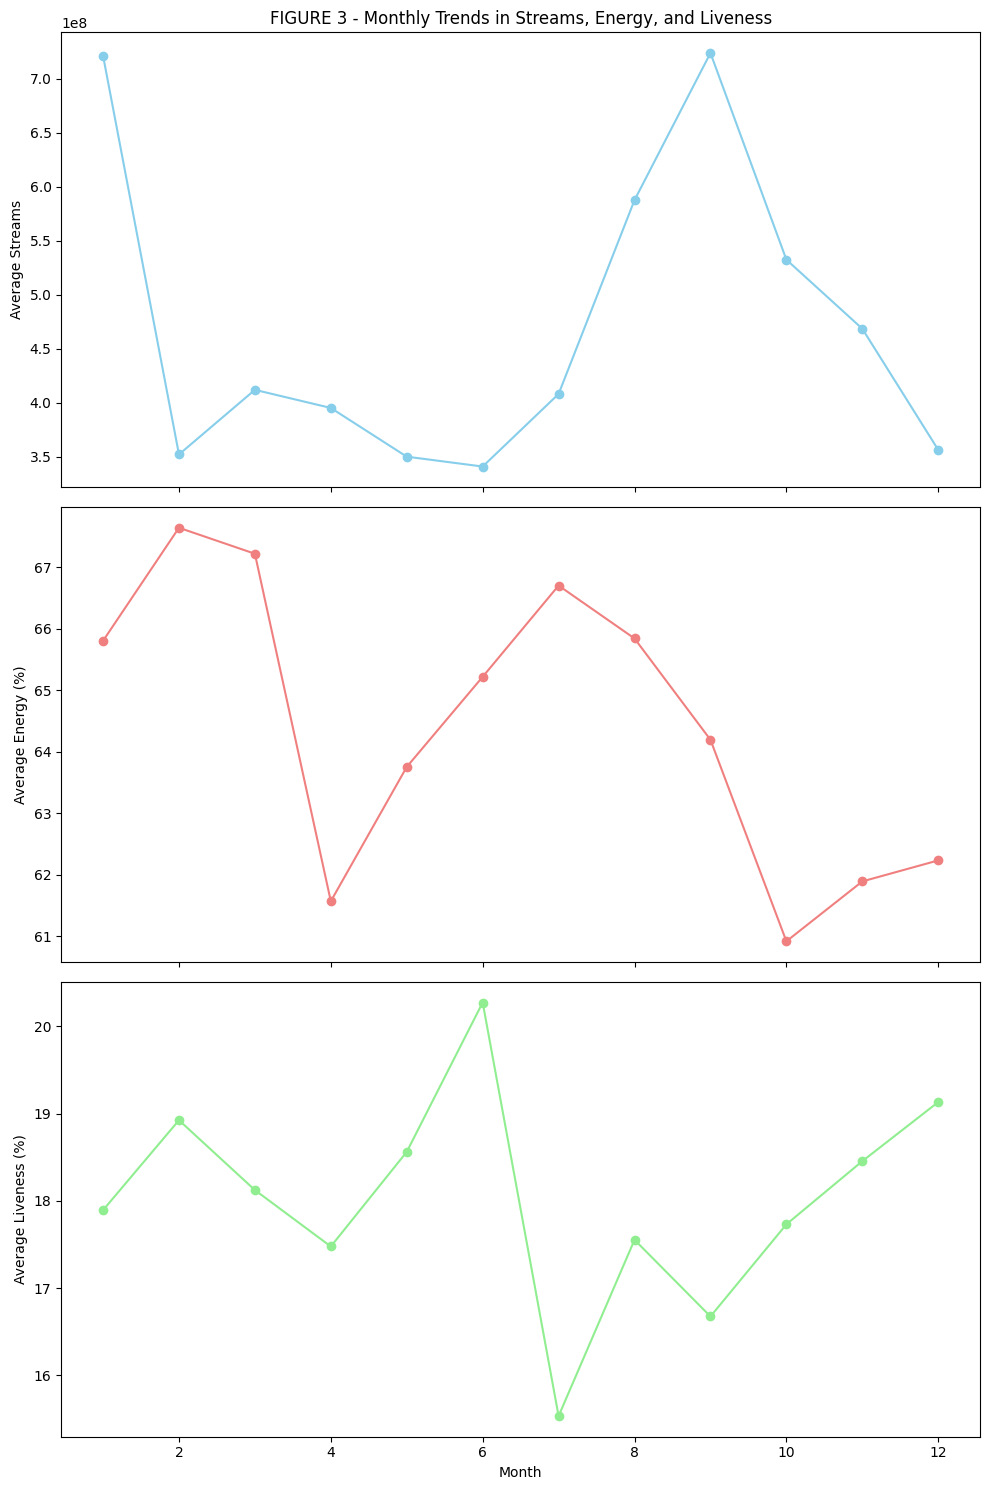

In [86]:
fig, axes = plt.subplots(3, 1, figsize=(10, 15), sharex=True)

# Plot average streams per month
axes[0].plot(monthly_trends.index, monthly_trends['streams'], marker='o', color='skyblue')
axes[0].set_ylabel('Average Streams')
axes[0].set_title('FIGURE 3 - Monthly Trends in Streams, Energy, and Liveness')

# Plot average energy per month
axes[1].plot(monthly_trends.index, monthly_trends['energy_%'], marker='o', color='lightcoral')
axes[1].set_ylabel('Average Energy (%)')

# Plot average liveness per month
axes[2].plot(monthly_trends.index, monthly_trends['liveness_%'], marker='o', color='lightgreen')
axes[2].set_ylabel('Average Liveness (%)')
axes[2].set_xlabel('Month')

plt.tight_layout()
plt.show()

Filter the DataFrame to include only songs released in November and December, calculate the average streams, energy, and liveness for this period, and then compare these averages to the overall averages of the dataset.



In [21]:
# Add the 'released_month_only' column
df['released_month_only'] = df['release_date'].dt.month

# Filter for November (11) and December (12) releases
holiday_season_df = df[df['released_month_only'].isin([11, 12])].copy()

# Calculate the average streams, energy, and liveness for the holiday season
holiday_season_avg = holiday_season_df[['streams', 'energy_%', 'liveness_%']].mean()

# Calculate the overall average streams, energy, and liveness
overall_avg = df[['streams', 'energy_%', 'liveness_%']].mean()

print("Average metrics for November and December releases:")
display(holiday_season_avg)

print("\nOverall average metrics:")
display(overall_avg)

# Compare the averages
print("\nComparison (Holiday Season Average vs. Overall Average):")
print(f"Streams: {holiday_season_avg['streams']:.2f} vs {overall_avg['streams']:.2f}")
print(f"Energy (%): {holiday_season_avg['energy_%']:.2f} vs {overall_avg['energy_%']:.2f}")
print(f"Liveness (%): {holiday_season_avg['liveness_%']:.2f} vs {overall_avg['liveness_%']:.2f}")

Average metrics for November and December releases:


,0
streams,4.640347e+08
energy_%,6.197419e+01
liveness_%,1.865806e+01



Overall average metrics:


,0
streams,5.141374e+08
energy_%,6.427912e+01
liveness_%,1.821301e+01



Comparison (Holiday Season Average vs. Overall Average):
Streams: 464034748.53 vs 514137424.94
Energy (%): 61.97 vs 64.28
Liveness (%): 18.66 vs 18.21


In [22]:
# Add the 'released_month_only' column
df['released_month_only'] = df['release_date'].dt.month

# Filter for November (11) and December (12) releases
holiday_season_df = df[df['released_month_only'].isin([11, 12])].copy()

# Calculate the average streams, energy, and liveness for the holiday season
holiday_season_avg = holiday_season_df[['streams', 'energy_%', 'liveness_%']].mean()

# Calculate the overall average streams, energy, and liveness
overall_avg = df[['streams', 'energy_%', 'liveness_%']].mean()

print("Average metrics for November and December releases:")
display(holiday_season_avg)

print("\nOverall average metrics:")
display(overall_avg)

# Compare the averages
print("\nComparison (Holiday Season Average vs. Overall Average):")
print(f"Streams: {holiday_season_avg['streams']:.2f} vs {overall_avg['streams']:.2f}")
print(f"Energy (%): {holiday_season_avg['energy_%']:.2f} vs {overall_avg['energy_%']:.2f}")
print(f"Liveness (%): {holiday_season_avg['liveness_%']:.2f} vs {overall_avg['liveness_%']:.2f}")

Average metrics for November and December releases:


,0
streams,4.640347e+08
energy_%,6.197419e+01
liveness_%,1.865806e+01



Overall average metrics:


,0
streams,5.141374e+08
energy_%,6.427912e+01
liveness_%,1.821301e+01



Comparison (Holiday Season Average vs. Overall Average):
Streams: 464034748.53 vs 514137424.94
Energy (%): 61.97 vs 64.28
Liveness (%): 18.66 vs 18.21


In [25]:
# Is Spotify ranking in the (Spotify) charts impacted more by streaming or presence in a Spotify playlist? Does a certain ranking increase the likelihood the song will be found in a user's playlist?



In [26]:
print("Descriptive statistics:")
display(df[['in_spotify_charts', 'streams', 'in_spotify_playlists']].describe())

print("\nData types:")
df[['in_spotify_charts', 'streams', 'in_spotify_playlists']].info()

print("\nMissing values:")
print(df[['in_spotify_charts', 'streams', 'in_spotify_playlists']].isnull().sum())

Descriptive statistics:


,in_spotify_charts,streams,in_spotify_playlists
count,953.000000,9.520000e+02,953.000000
mean,12.009444,5.141374e+08,5200.124869
std,19.575992,5.668569e+08,7897.608990
min,0.000000,2.762000e+03,31.000000
25%,0.000000,1.416362e+08,875.000000
50%,3.000000,2.905309e+08,2224.000000
75%,16.000000,6.738690e+08,5542.000000
max,147.000000,3.703895e+09,52898.000000



Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   in_spotify_charts     953 non-null    int64  
 1   streams               952 non-null    float64
 2   in_spotify_playlists  953 non-null    int64  
dtypes: float64(1), int64(2)
memory usage: 22.5 KB

Missing values:
in_spotify_charts       0
streams                 1
in_spotify_playlists    0
dtype: int64


## Calculate correlations

### Subtask:
Calculate the correlation coefficients between 'in_spotify_charts', 'streams', and 'in_spotify_playlists' to quantify their linear relationships.


**Reasoning**:
Calculate the correlation coefficients between the specified columns to quantify their linear relationships.



In [42]:
# Select the relevant columns
correlation_columns = df[['in_spotify_charts', 'streams', 'in_spotify_playlists']]

# Calculate the correlation matrix
correlation_matrix_subset = correlation_columns.corr()

# Display the correlation matrix


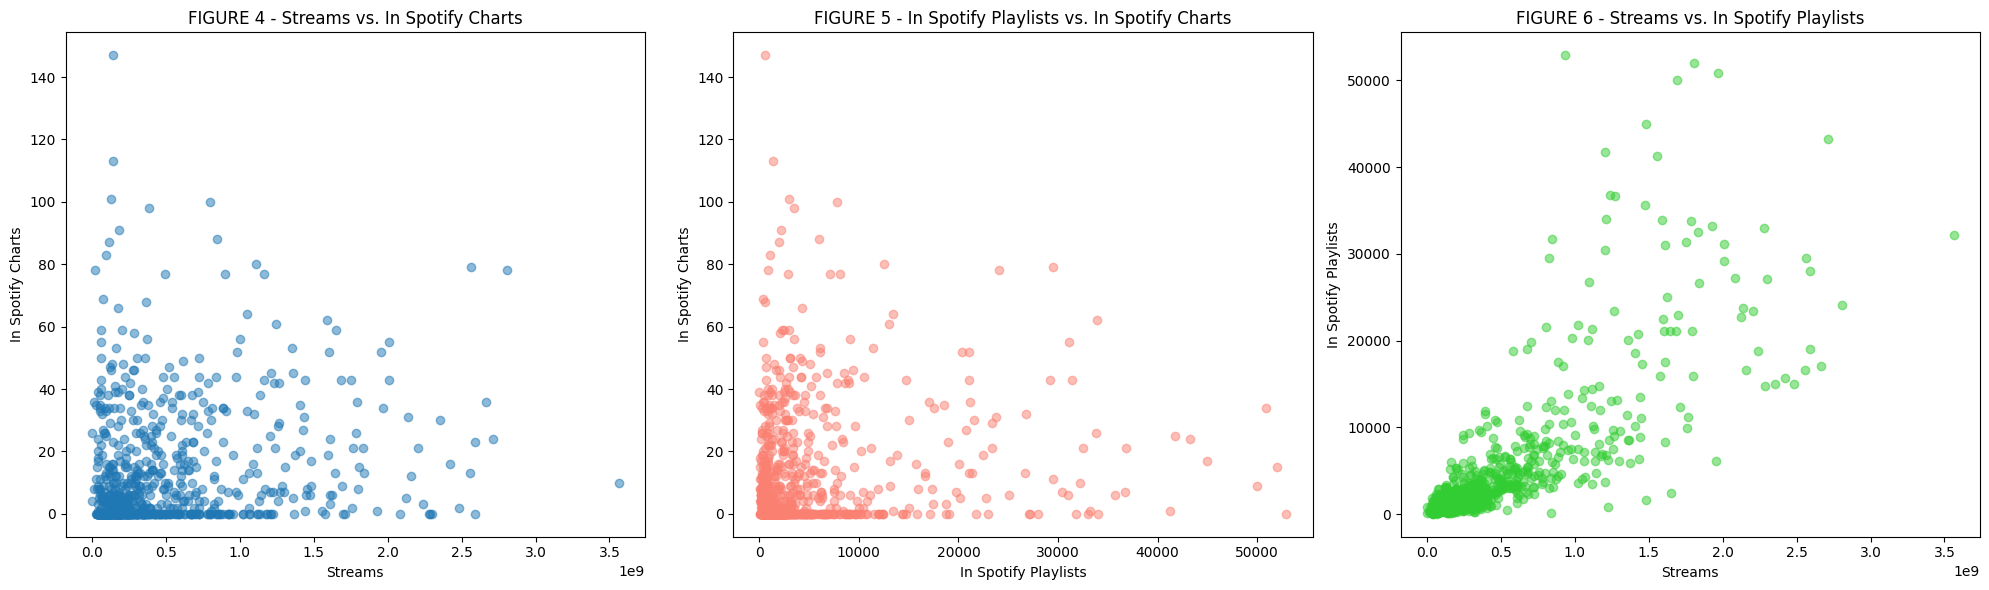

In [87]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Scatter plot 1: Streams vs. In Spotify Charts
axes[0].scatter(df['streams'], df['in_spotify_charts'], alpha=0.5)
axes[0].set_xlabel('Streams')
axes[0].set_ylabel('In Spotify Charts')
axes[0].set_title('FIGURE 4 - Streams vs. In Spotify Charts')

# Scatter plot 2: In Spotify Playlists vs. In Spotify Charts
axes[1].scatter(df['in_spotify_playlists'], df['in_spotify_charts'], alpha=0.5, color='salmon')
axes[1].set_xlabel('In Spotify Playlists')
axes[1].set_ylabel('In Spotify Charts')
axes[1].set_title('FIGURE 5 - In Spotify Playlists vs. In Spotify Charts')

# Scatter plot 3: Streams vs. In Spotify Playlists
axes[2].scatter(df['streams'], df['in_spotify_playlists'], alpha=0.5, color='limegreen')
axes[2].set_xlabel('Streams')
axes[2].set_ylabel('In Spotify Playlists')
axes[2].set_title('FIGURE 6 - Streams vs. In Spotify Playlists')

plt.tight_layout()
plt.show()

In [43]:
playlist_counts_by_chart = df.groupby('in_spotify_charts')['in_spotify_playlists'].mean()


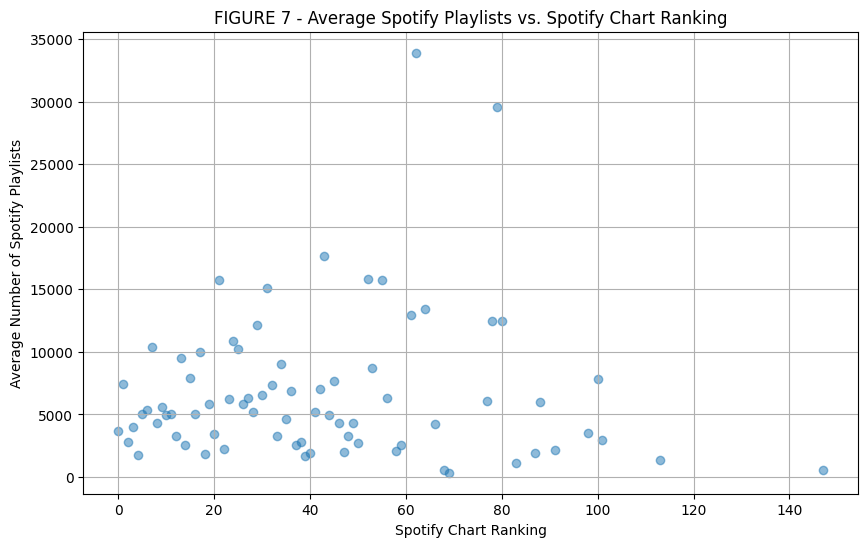

In [88]:
plt.figure(figsize=(10, 6))
plt.scatter(playlist_counts_by_chart.index, playlist_counts_by_chart.values, alpha=0.5)
plt.xlabel('Spotify Chart Ranking')
plt.ylabel('Average Number of Spotify Playlists')
plt.title('FIGURE 7 - Average Spotify Playlists vs. Spotify Chart Ranking')
plt.grid(True)
plt.show()

Visualized the impact of streaming and playlist presence on chart ranking, and whether ranking influences playlist inclusion.


1.  **Relation between streams and playlist presence.**
    Both a higher number of streams and inclusion in more Spotify playlists are associated with a better (lower) ranking in the Spotify charts. The analysis showed a strong positive correlation between streams and chart presence (0.246) and a moderate positive correlation between playlist presence and chart presence (0.164). Visualizations supported these findings, showing an upward trend in chart ranking as streams and playlist presence increased.


2.  **Impact of a song's ranking in Spotify charts influences its inclusion in Spotify playlists**
    The analysis suggests that achieving a higher ranking in the Spotify charts might lead to increased inclusion in Spotify playlists. The average number of Spotify playlists a song is included in generally increases as the chart ranking improves (gets lower).

#### Key Findings

*   There is a strong positive correlation (0.790) between the number of streams a song has and its inclusion in Spotify playlists.
*   There is a weak positive correlation (0.246) between a song's presence in Spotify charts and its number of streams.
*   There is a very weak positive correlation (0.164) between a song's presence in Spotify charts and its inclusion in Spotify playlists.
*   Songs with higher rankings (lower numbers) in Spotify charts tend to be included in a higher average number of Spotify playlists.


### **OBJECTIVE THREE:**

Using the single most (intrinsic) predictive feature identified does this feature help predict popularity to the same degree if the 2024 Spotify data is also used?

Build a predictive model to predict 'streams' using the available features in the dataset.

*   Prepare the data for modeling, including handling any remaining missing values, selecting relevant features, and splitting the data into training and testing sets.
*   Drop rows with missing values, select numerical features for predictors, define the target variable, and split the data into training and testing sets to prepare for modeling.

In [31]:
# Drop rows with missing values
df.dropna(inplace=True)

# Select numerical features as predictors (excluding 'streams')
numerical_features = df.select_dtypes(include=np.number).columns.tolist()
predictor_features = [feature for feature in numerical_features if feature != 'streams']
X = df[predictor_features]

# Define the target variable
y = df['streams']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (652, 20)
Shape of X_test: (164, 20)
Shape of y_train: (652,)
Shape of y_test: (164,)


In [32]:
from sklearn.linear_model import LinearRegression

# Instantiate the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model training complete.")

Model training complete.


In [33]:
# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

# Calculate R-squared score
r2 = r2_score(y_test, y_pred)

# Print the evaluation metrics
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared Score: {r2:.2f}")

Mean Squared Error (MSE): 76128710925559696.00
R-squared Score: 0.75


In [34]:
# Access the coefficients of the trained model
coefficients = model.coef_

# Pair the coefficients with their corresponding feature names
feature_coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': coefficients
})

# Sort the coefficients by their absolute values in descending order
sorted_coefficients = feature_coefficients.reindex(feature_coefficients['Coefficient'].abs().sort_values(ascending=False).index)

# Display the sorted feature coefficients
print("Sorted Feature Coefficients (by absolute value):")
display(sorted_coefficients)

Sorted Feature Coefficients (by absolute value):


,Feature,Coefficient
0,artist_count,-2.863035e+07
10,mode,-2.145322e+07
8,in_deezer_charts,-3.990943e+06
1,released_year,3.077715e+06
6,in_apple_playlists,2.864458e+06
5,in_spotify_charts,2.837871e+06
18,release_month_only,1.486279e+06
2,released_month,1.486279e+06
19,released_month_only,1.486279e+06
13,energy_%,-1.350293e+06


In [35]:
# Define the list of features to consider
selected_features = [
    'artist(s)_name', 'bpm', 'key', 'mode', 'danceability_%',
    'valence_%', 'energy_%', 'acousticness_%', 'instrumentalness_%',
    'liveness_%', 'speechiness_%'
]

# Filter the streams correlations to include only the selected features
filtered_streams_correlations = streams_correlations[streams_correlations.index.isin(selected_features)]

# Get the top 5 features from the filtered list
top_5_predictors_subset = filtered_streams_correlations.head(5)

print("Top 5 predictors of streams from the selected features:")
display(top_5_predictors_subset)

# Get the bottom 5 features from the filtered list
bottom_5_predictors_subset = filtered_streams_correlations.tail(5)

print("Bottom 5 predictors of streams from the selected features:")
display(bottom_5_predictors_subset)

Top 5 predictors of streams from the selected features:


,streams
speechiness_%,0.112333
danceability_%,0.105457
liveness_%,0.048337
instrumentalness_%,0.044902
mode,0.042635


Bottom 5 predictors of streams from the selected features:


,streams
mode,0.042635
valence_%,0.040831
energy_%,0.026051
acousticness_%,0.004485
bpm,0.002438


Upload and load a new dataset for 2024, similar in structure to the existing 2023 dataset, into a pandas DataFrame for comparison.

In [45]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path1 = "Most Streamed Spotify Songs 2024.csv"
# Make sure this is the correct file name from the dataset

# Load the latest version
df_2024 = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "nelgiriyewithana/most-streamed-spotify-songs-2024", # This is the dataset handle
  file_path1, # This is the file name within the dataset
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
  pandas_kwargs={'encoding': 'latin-1'} # Added encoding for consistency
)

#### Comparing 2023 and 2024 Datasets

Compare the structure and content of the "spotify_2023.csv" and "spotify_2024.csv" datasets, identify common features, explore their distributions, and determine the top 5 predictors of a song appearing in the streaming category in the 2023 dataset based on the specified features. Would like to use the single most predictive factor for comparison.

#### **FEATURES in the 2024 Spotify Data**

*   Track Name: Name of the song.
*   Album Name: Name of the album the song belongs to.
*   Artist: Name of the artist(s) of the song.
*   Release Date: Date when the song was released.
*   ISRC: International Standard Recording Code for the song.
*   All Time Rank: Ranking of the song based on its all-time popularity.
*   Track Score: Score assigned to the track based on various factors.
*   Spotify Streams: Total number of streams on Spotify.
*   Spotify Playlist Count: Number of Spotify playlists the song is included in.
*   Spotify Playlist Reach: Reach of the song across Spotify playlists.
*   Spotify Popularity: Popularity score of the song on Spotify.
*   YouTube Views: Total views of the song's official video on YouTube.
*   YouTube Likes: Total likes on the song's official video on YouTube.
*   TikTok Posts: Number of TikTok posts featuring the song.
*   TikTok Likes: Total likes on TikTok posts featuring the song.
*   TikTok Views: Total views on TikTok posts featuring the song.
*   YouTube Playlist Reach: Reach of the song across YouTube playlists.
*   Apple Music Playlist Count: Number of Apple Music playlists the song is included in.
*   AirPlay Spins: Number of times the song has been played on radio stations.
*   SiriusXM Spins: Number of times the song has been played on SiriusXM.
*   Deezer Playlist Count: Number of Deezer playlists the song is included in.
*   Deezer Playlist Reach: Reach of the song across Deezer playlists.
*   Amazon Playlist Count: Number of Amazon Music playlists the song is included in.
*   Pandora Streams: Total number of streams on Pandora.
*   Pandora Track Stations: Number of Pandora stations featuring the song.
*   Soundcloud Streams: Total number of streams on Soundcloud.
*   Shazam Counts: Total number of times the song has been Shazamed.
*   TIDAL Popularity: Popularity score of the song on TIDAL.
*   Explicit Track: Indicates whether the song contains explicit content.

In [47]:
print(df_2024.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Track                       4600 non-null   object 
 1   Album Name                  4600 non-null   object 
 2   Artist                      4595 non-null   object 
 3   Release Date                4600 non-null   object 
 4   ISRC                        4600 non-null   object 
 5   All Time Rank               4600 non-null   object 
 6   Track Score                 4600 non-null   float64
 7   Spotify Streams             4487 non-null   object 
 8   Spotify Playlist Count      4530 non-null   object 
 9   Spotify Playlist Reach      4528 non-null   object 
 10  Spotify Popularity          3796 non-null   float64
 11  YouTube Views               4292 non-null   object 
 12  YouTube Likes               4285 non-null   object 
 13  TikTok Posts                3427 

In [49]:
# Identify missing data or NaN data in different columns
# Filter the DataFrame to show rows where 'Artist' is missing
missing_artist_rows = df_2024[df_2024['Artist'].isnull()]

# Display the rows with missing 'Artist' information
print("Rows with missing 'Artist' information:")
display(missing_artist_rows)

Rows with missing 'Artist' information:


,Track,Album Name,Artist,Release Date,ISRC,All Time Rank,Track Score,Spotify Streams,Spotify Playlist Count,Spotify Playlist Reach,...,SiriusXM Spins,Deezer Playlist Count,Deezer Playlist Reach,Amazon Playlist Count,Pandora Streams,Pandora Track Stations,Soundcloud Streams,Shazam Counts,TIDAL Popularity,Explicit Track
311,Cool,JnD Mix,NaN,5/25/2024,QZNWQ2410638,311,86.5,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"8,624,577",NaN,0
480,I Wanna Party,I Wanna Party - Single,NaN,5/31/2024,QZYFZ2445017,482,70.3,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1345,Marlboro Remix,Marlboro Remix - Single,NaN,6/7/2024,QZNWT2471497,"1,343",40.6,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"504,979",NaN,0
1561,Melting,Melting - Single,NaN,6/10/2024,QZNWU2402635,"1,553",37.2,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"289,134",NaN,0
3402,La ï¿½ï¿½ltima Vez (Yo Te Per,La ï¿½ï¿½ltima Vez (Yo Te Perdï¿½ï¿½),NaN,5/2/2024,MX2832415361,"3,381",23.6,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,606,561",NaN,0


*Would have compared Artist popularity but too many NaN values in the 2024 dataset.*




In [50]:
print("Columns in 2023 dataset:")
print(df.columns)

print("\nColumns in 2024 dataset:")
print(df_2024.columns)

Columns in 2023 dataset:
Index(['track_name', 'artist(s)_name', 'artist_count', 'released_year',
       'released_month', 'released_day', 'in_spotify_playlists',
       'in_spotify_charts', 'streams', 'in_apple_playlists', 'in_apple_charts',
       'in_deezer_playlists', 'in_deezer_charts', 'in_shazam_charts', 'bpm',
       'key', 'mode', 'danceability_%', 'valence_%', 'energy_%',
       'acousticness_%', 'instrumentalness_%', 'liveness_%', 'speechiness_%',
       'release_date', 'release_month_only', 'released_month_only',
       'released_date'],
      dtype='object')

Columns in 2024 dataset:
Index(['Track', 'Album Name', 'Artist', 'Release Date', 'ISRC',
       'All Time Rank', 'Track Score', 'Spotify Streams',
       'Spotify Playlist Count', 'Spotify Playlist Reach',
       'Spotify Popularity', 'YouTube Views', 'YouTube Likes', 'TikTok Posts',
       'TikTok Likes', 'TikTok Views', 'YouTube Playlist Reach',
       'Apple Music Playlist Count', 'AirPlay Spins', 'SiriusXM Spins',


*Identify common columns manually by comparing the column names from `df.columns` and `df_2024.columns`.*



In [51]:
# Manually identified common/similar features:
common_features = [
    ('track_name', 'Track'),
    ('artist(s)_name', 'Artist'),
    ('released_year', 'Release Date'), # Year can be extracted from Release Date
    ('released_month', 'Release Date'), # Month can be extracted from Release Date
    ('released_day', 'Release Date'),   # Day can be extracted from Release Date
    ('in_spotify_playlists', 'Spotify Playlist Count'),
    ('in_spotify_charts', 'All Time Rank'), # Both represent ranking/presence
    ('streams', 'Spotify Streams'),
    ('in_apple_playlists', 'Apple Music Playlist Count'),
    ('in_deezer_playlists', 'Deezer Playlist Count'),
    ('in_shazam_charts', 'Shazam Counts'),
    ('bpm', None), # BPM is in 2023 but not directly in 2024
    ('key', None), # Key is in 2023 but not directly in 2024
    ('mode', None), # Mode is in 2023 but not directly in 2024
    ('danceability_%', None), # Audio features are in 2023 but not directly in 2024
    ('valence_%', None),
    ('energy_%', None),
    ('acousticness_%', None),
    ('instrumentalness_%', None),
    ('liveness_%', None),
    ('speechiness_%', None),
    (None, 'Album Name'), # Album Name is in 2024 but not directly in 2023
    (None, 'ISRC'),
    (None, 'Track Score'),
    (None, 'Spotify Playlist Reach'),
    (None, 'Spotify Popularity'),
    (None, 'YouTube Views'),
    (None, 'YouTube Likes'),
    (None, 'TikTok Posts'),
    (None, 'TikTok Likes'),
    (None, 'TikTok Views'),
    (None, 'YouTube Playlist Reach'),
    (None, 'AirPlay Spins'),
    (None, 'SiriusXM Spins'),
    (None, 'Deezer Playlist Reach'),
    (None, 'Amazon Playlist Count'),
    (None, 'Pandora Streams'),
    (None, 'Pandora Track Stations'),
    (None, 'Soundcloud Streams'),
    (None, 'TIDAL Popularity'),
    (None, 'Explicit Track')
]

print("Common or similar features between 2023 and 2024 datasets:")
for common in common_features:
    if common[0] and common[1]:
        print(f"- 2023: '{common[0]}' - 2024: '{common[1]}'")
    elif common[0]:
        print(f"- 2023: '{common[0]}' - 2024: (Not directly present)")
    elif common[1]:
        print(f"- 2023: (Not directly present) - 2024: '{common[1]}'")

Common or similar features between 2023 and 2024 datasets:
- 2023: 'track_name' - 2024: 'Track'
- 2023: 'artist(s)_name' - 2024: 'Artist'
- 2023: 'released_year' - 2024: 'Release Date'
- 2023: 'released_month' - 2024: 'Release Date'
- 2023: 'released_day' - 2024: 'Release Date'
- 2023: 'in_spotify_playlists' - 2024: 'Spotify Playlist Count'
- 2023: 'in_spotify_charts' - 2024: 'All Time Rank'
- 2023: 'streams' - 2024: 'Spotify Streams'
- 2023: 'in_apple_playlists' - 2024: 'Apple Music Playlist Count'
- 2023: 'in_deezer_playlists' - 2024: 'Deezer Playlist Count'
- 2023: 'in_shazam_charts' - 2024: 'Shazam Counts'
- 2023: 'bpm' - 2024: (Not directly present)
- 2023: 'key' - 2024: (Not directly present)
- 2023: 'mode' - 2024: (Not directly present)
- 2023: 'danceability_%' - 2024: (Not directly present)
- 2023: 'valence_%' - 2024: (Not directly present)
- 2023: 'energy_%' - 2024: (Not directly present)
- 2023: 'acousticness_%' - 2024: (Not directly present)
- 2023: 'instrumentalness_%' - 20

In [53]:
rename_map = {
    'Track': 'track_name',
    'Artist': 'artist(s)_name',
    'Spotify Playlist Count': 'in_spotify_playlists',
    'All Time Rank': 'in_spotify_charts',
    'Spotify Streams': 'streams',
    'Apple Music Playlist Count': 'in_apple_playlists',
    'Deezer Playlist Count': 'in_deezer_playlists',
    'Shazam Counts': 'in_shazam_charts'
}

df_2024.rename(columns=rename_map, inplace=True)


In [54]:
df_2024['release_date'] = pd.to_datetime(df_2024['Release Date'], errors='coerce')
df_2024['released_year'] = df_2024['release_date'].dt.year
df_2024['released_month'] = df_2024['release_date'].dt.month
df_2024['released_day'] = df_2024['release_date'].dt.day


In [56]:
columns_to_convert = [
    'streams', 'in_spotify_playlists', 'Spotify Playlist Reach',
    'YouTube Views', 'YouTube Likes', 'TikTok Posts', 'TikTok Likes',
    'TikTok Views', 'YouTube Playlist Reach', 'AirPlay Spins',
    'SiriusXM Spins', 'Deezer Playlist Reach', 'Pandora Streams',
    'Pandora Track Stations', 'Soundcloud Streams', 'in_shazam_charts'
]

for col in columns_to_convert:
    if col in df_2024.columns:
        # Remove commas and convert to numeric, coercing errors to NaN
        df_2024[col] = df_2024[col].astype(str).str.replace(',', '', regex=False)
        df_2024[col] = pd.to_numeric(df_2024[col], errors='coerce')


FIGURE 8 - Common numerical columns for comparison: ['in_spotify_playlists', 'in_apple_playlists', 'streams', 'released_month', 'released_day', 'released_year']


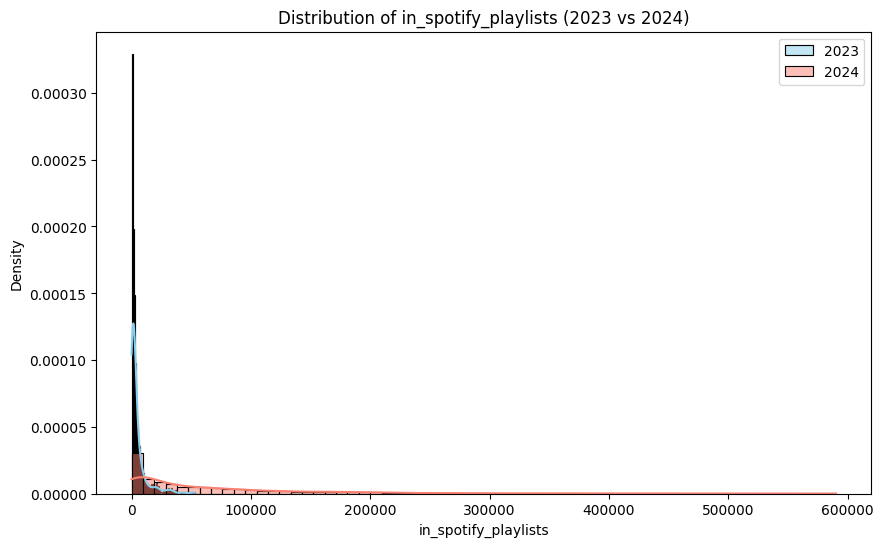

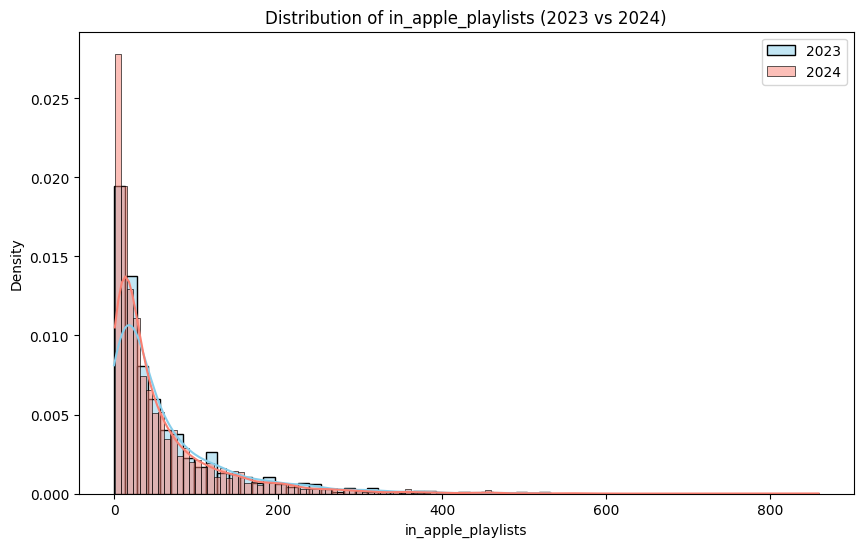

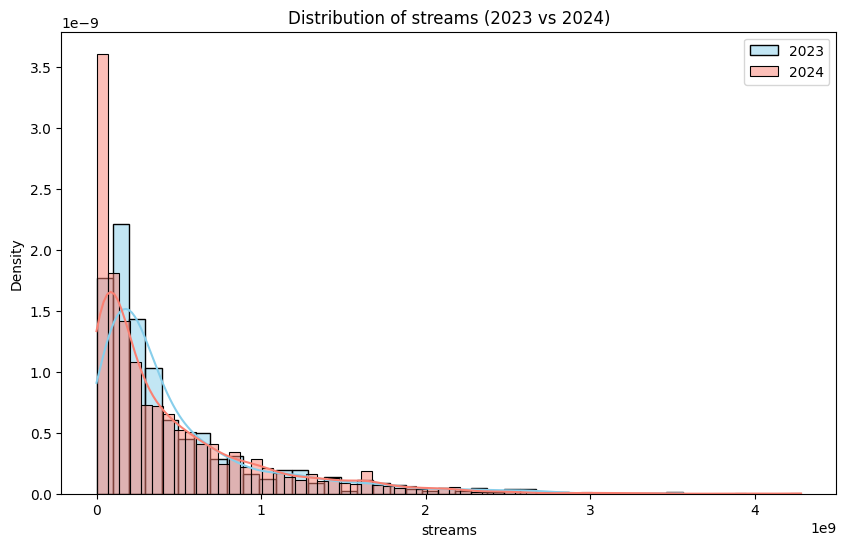

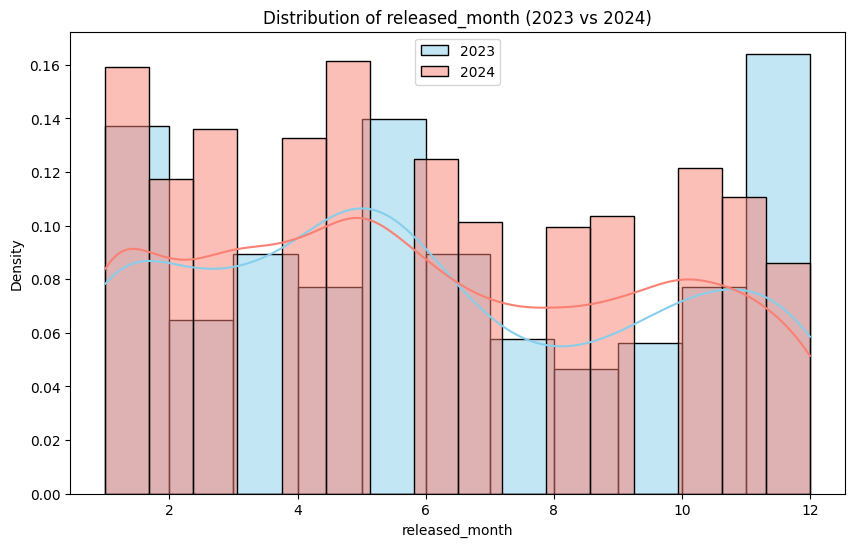

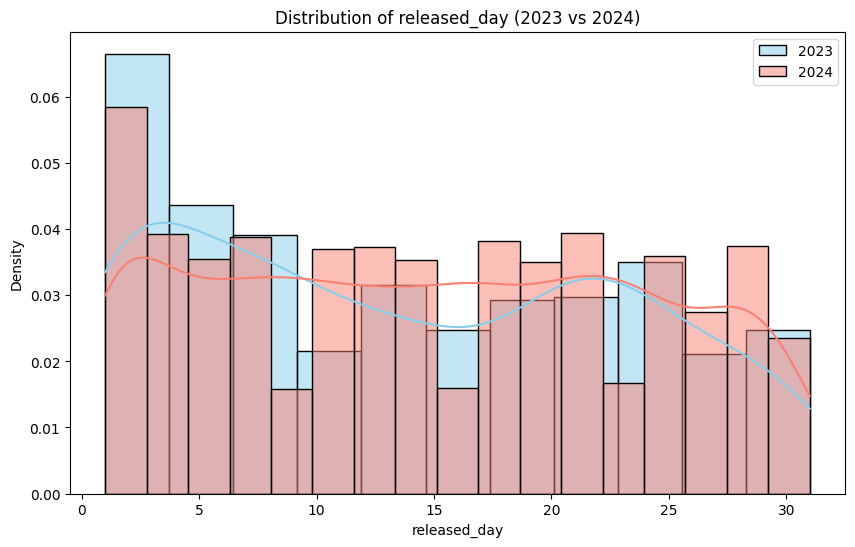

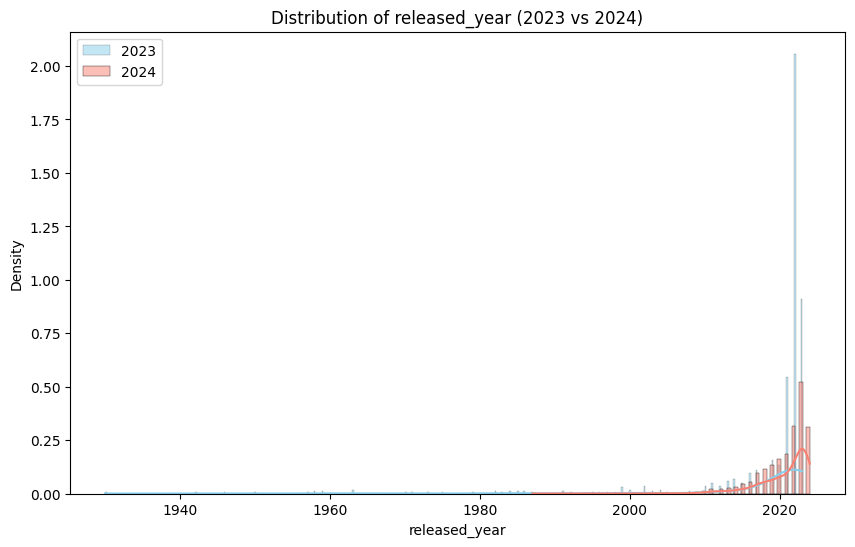

In [89]:
# Identify common numerical columns after cleaning and standardization
common_numerical_cols = list(set(df.select_dtypes(include=np.number).columns) & set(df_2024.select_dtypes(include=np.number).columns))

# Exclude the newly created date columns in df from the comparison if they are not in df_2024
common_numerical_cols = [col for col in common_numerical_cols if col not in ['release_month_only', 'released_month_only', 'released_date']]

print("FIGURE 8 - Common numerical columns for comparison:", common_numerical_cols)

# Visualize the distribution of common numerical features
for col in common_numerical_cols:
    plt.figure(figsize=(10, 6))
    sns.histplot(df[col].dropna(), color='skyblue', label='2023', kde=True, stat='density', common_norm=False)
    sns.histplot(df_2024[col].dropna(), color='salmon', label='2024', kde=True, stat='density', common_norm=False)
    plt.title(f'Distribution of {col} (2023 vs 2024)')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.legend()
    plt.show()

In [58]:
# Identify common numerical columns again, ensuring consistency after previous steps
common_numerical_cols = list(set(df.select_dtypes(include=np.number).columns) & set(df_2024.select_dtypes(include=np.number).columns))

# Exclude the newly created date columns in df from the comparison if they are not in df_2024
common_numerical_cols = [col for col in common_numerical_cols if col not in ['release_month_only', 'released_month_only', 'released_date']]

print("Descriptive statistics for common numerical columns (2023):")
display(df[common_numerical_cols].describe())

print("\nDescriptive statistics for common numerical columns (2024):")
display(df_2024[common_numerical_cols].describe())

Descriptive statistics for common numerical columns (2023):


,in_spotify_playlists,in_apple_playlists,streams,released_month,released_day,released_year
count,816.000000,816.000000,8.160000e+02,816.000000,816.000000,816.000000
mean,4852.316176,60.215686,4.689858e+08,6.024510,13.712010,2018.517157
std,7745.565488,74.953565,5.231267e+08,3.570415,9.294719,10.701973
min,31.000000,0.000000,2.762000e+03,1.000000,1.000000,1930.000000
25%,829.000000,12.000000,1.342848e+08,3.000000,5.000000,2021.000000
50%,2037.500000,32.000000,2.638368e+08,5.000000,13.000000,2022.000000
75%,4890.750000,78.250000,6.011986e+08,9.000000,22.000000,2022.000000
max,52898.000000,532.000000,3.562544e+09,12.000000,31.000000,2023.000000



Descriptive statistics for common numerical columns (2024):


,in_spotify_playlists,in_apple_playlists,streams,released_month,released_day,released_year
count,4530.000000,4039.00000,4.487000e+03,4600.000000,4600.000000,4600.000000
mean,59390.829801,54.60312,4.473873e+08,6.046304,14.871957,2020.616739
std,71131.406625,71.61227,5.384439e+08,3.419663,9.041923,3.611707
min,1.000000,1.00000,1.071000e+03,1.000000,1.000000,1987.000000
25%,6718.000000,10.00000,7.038630e+07,3.000000,7.000000,2019.000000
50%,32312.500000,28.00000,2.398507e+08,6.000000,15.000000,2022.000000
75%,86038.750000,70.00000,6.283638e+08,9.000000,22.000000,2023.000000
max,590392.000000,859.00000,4.281469e+09,12.000000,31.000000,2024.000000


In [60]:
df_2024['release_date'] = pd.to_datetime(df_2024['Release Date'], errors='coerce')
df_2024['released_year'] = df_2024['release_date'].dt.year
df_2024['released_month'] = df_2024['release_date'].dt.month
df_2024['released_day'] = df_2024['release_date'].dt.day


In [64]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd

# Load the 2024 dataset again
file_path_2024 = "Most Streamed Spotify Songs 2024.csv"
df_2024_original = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "nelgiriyewithana/most-streamed-spotify-songs-2024",
  file_path_2024,
  pandas_kwargs={'encoding': 'latin-1'}
)


In [66]:
import re

# Reload the original 2024 dataset if not already loaded
# file_path_2024 = "Most Streamed Spotify Songs 2024.csv"
# df_2024_original = kagglehub.load_dataset(
#   KaggleDatasetAdapter.PANDAS,
#   "nelgiriyewithana/most-streamed-spotify-songs-2024",
#   file_path_2024,
#   pandas_kwargs={'encoding': 'latin-1'}
# )

# Define a function to check for non-numeric characters (excluding comma)
def find_non_numeric(value):
    if isinstance(value, str):
        # Find any character that is NOT a digit (0-9) or a comma (,)
        non_numeric_chars = re.findall(r'[^\d,]', value)
        if non_numeric_chars:
            return ''.join(non_numeric_chars)
    return None

# Apply the function to the 'Spotify Streams' column and get unique non-numeric characters
non_numeric_issues = df_2024_original['Spotify Streams'].apply(find_non_numeric).dropna().unique()


In [67]:
# Reload the original 2024 dataset to start with the raw data for this column
file_path_2024 = "Most Streamed Spotify Songs 2024.csv"
df_2024_reloaded = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "nelgiriyewithana/most-streamed-spotify-songs-2024",
  file_path_2024,
  pandas_kwargs={'encoding': 'latin-1'}
)

# Keep a copy of the original streams column for inspection
original_streams_2024 = df_2024_reloaded['Spotify Streams'].copy()

# Remove commas from the streams column
cleaned_streams_2024 = original_streams_2024.astype(str).str.replace(',', '', regex=False)

# Attempt to convert to numeric, keeping track of errors
numeric_streams_2024 = pd.to_numeric(cleaned_streams_2024, errors='coerce')

# Find the values that were coerced to NaN
problematic_streams_values = original_streams_2024[numeric_streams_2024.isnull()]

# Assign the successfully converted numeric streams back to the main df_2024 DataFrame
# Note: This will overwrite the current 'streams' column in df_2024
df_2024['streams'] = numeric_streams_2024


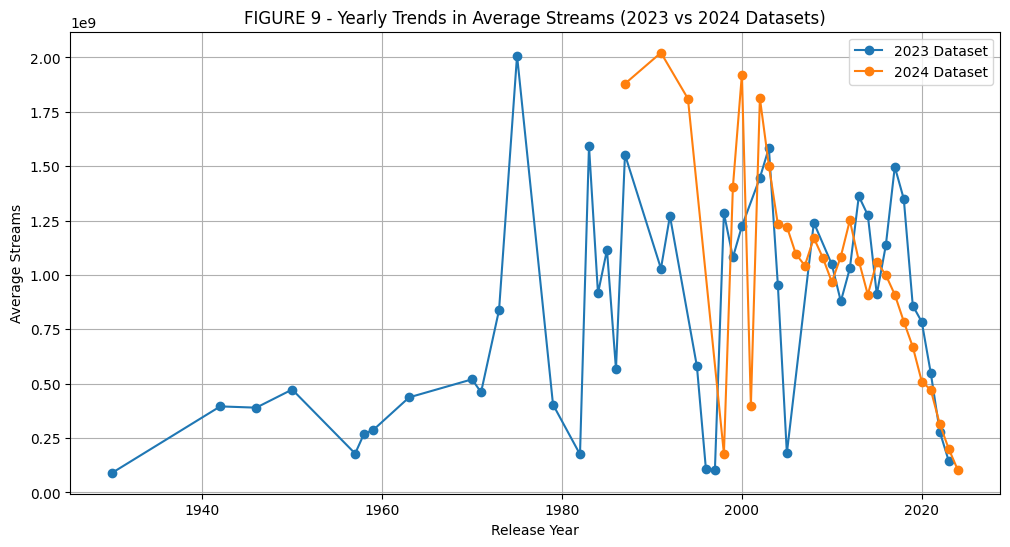

In [90]:
# Calculate yearly average streams for 2023 dataset
yearly_streams_2023 = df.groupby('released_year')['streams'].mean().reset_index()

# Calculate yearly average streams for 2024 dataset, dropping NaN streams
yearly_streams_2024 = df_2024.dropna(subset=['streams']).groupby('released_year')['streams'].mean().reset_index()


# Visualize the yearly trends
plt.figure(figsize=(12, 6))
plt.plot(yearly_streams_2023['released_year'], yearly_streams_2023['streams'], marker='o', label='2023 Dataset')
plt.plot(yearly_streams_2024['released_year'], yearly_streams_2024['streams'], marker='o', label='2024 Dataset')

plt.title('FIGURE 9 - Yearly Trends in Average Streams (2023 vs 2024 Datasets)')
plt.xlabel('Release Year')
plt.ylabel('Average Streams')
plt.legend()
plt.grid(True)
plt.show()

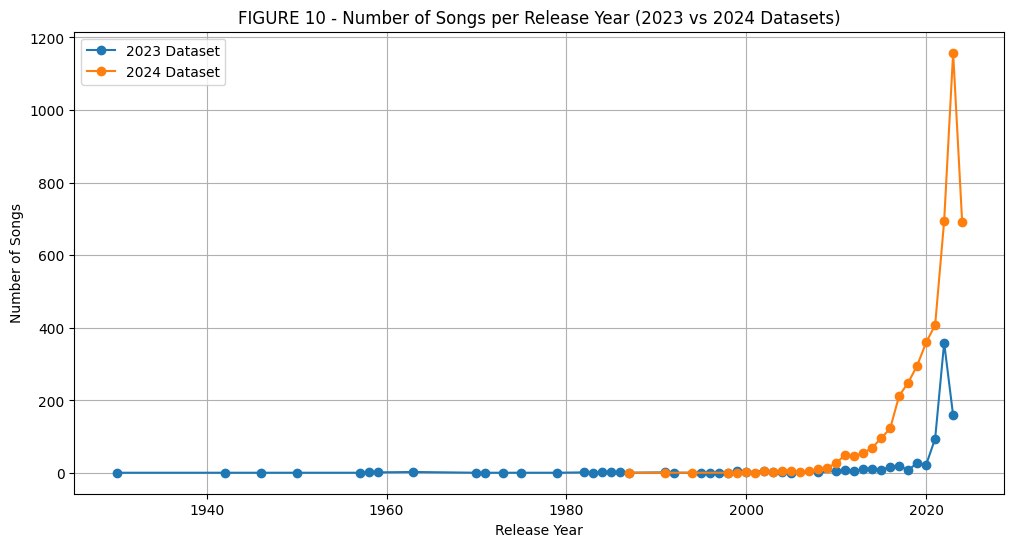

In [91]:
# Calculate the number of songs per release year for 2023 dataset
yearly_counts_2023 = df.groupby('released_year').size().reset_index(name='song_count')

# Calculate the number of songs per release year for 2024 dataset
yearly_counts_2024 = df_2024.groupby('released_year').size().reset_index(name='song_count')

# Visualize the yearly counts
plt.figure(figsize=(12, 6))
plt.plot(yearly_counts_2023['released_year'], yearly_counts_2023['song_count'], marker='o', label='2023 Dataset')
plt.plot(yearly_counts_2024['released_year'], yearly_counts_2024['song_count'], marker='o', label='2024 Dataset')

plt.title('FIGURE 10 - Number of Songs per Release Year (2023 vs 2024 Datasets)')
plt.xlabel('Release Year')
plt.ylabel('Number of Songs')
plt.legend()
plt.grid(True)
plt.show()

***Here is the summary of the findings from our analysis of yearly trends in both the 2023 and 2024 datasets:***

*Distribution of Songs by Release Year:
The 2023 dataset contains the highest number of songs released in 2022.
The 2024 dataset contains the highest number of songs released in 2023.
Both datasets include songs released in various years, with a concentration on more recent releases, but also including some older tracks.
Average Streams by Release Year:
The trend in average streams per release year differs between the two datasets.
In both datasets, there's a general tendency for more recent releases to have higher average streams, which is expected as these are "most streamed" lists.
However, the 2024 dataset shows some older release years with very high average stream counts. This is likely due to the inclusion of a smaller number of exceptionally popular older songs in the 204 dataset, which significantly increases the average for those years, even if they don't represent the majority of songs in the dataset. The 2023 dataset also shows some fluctuations for older years, but the effect seems more pronounced in the 2024 data.
In essence, while the datasets primarily feature recent hits, the inclusion of highly streamed older tracks in the 2024 dataset creates a different pattern in the average streams per year compared to the 2023 dataset.*



In [71]:
# Get the top 10 feature names
top_10_features = streams_correlations.head(10).index.tolist()

# Create predictor and target variables
X = df[top_10_features]
y = df['streams']

# Display the first 5 rows of X and y


*I need to split the data into training and testing sets to prepare for model training and evaluation. I will use the `train_test_split` function from `sklearn.model_selection` to perform this split. *



In [73]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [74]:
from sklearn.linear_model import LinearRegression

# Instantiate the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model training complete.")

Model training complete.


In [76]:
# Drop rows with missing values in 'streams'
df.dropna(subset=['streams'], inplace=True)

# Recreate X and y after dropping NaNs
top_10_features = streams_correlations.head(10).index.tolist()
X = df[top_10_features]
y = df['streams']

# Split the data again
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Instantiate and train the model
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

*Now that the model is trained, the next logical step is to evaluate its performance on the test set. I will use the trained model to make predictions on `X_test` and then calculate and print the Mean Squared Error (MSE) and R-squared score to assess the model's accuracy.*



In [77]:
# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

# Calculate R-squared score
r2 = r2_score(y_test, y_pred)

# Print the evaluation metrics
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared Score: {r2:.2f}")

Mean Squared Error (MSE): 78074584188007456.00
R-squared Score: 0.75


*The model has been trained and evaluated. To better understand the results, I will create a scatter plot to visualize the relationship between the actual stream counts (`y_test`) and the model's predictions (`y_pred`). I will also add a line representing perfect predictions to help assess the model's accuracy visually.*



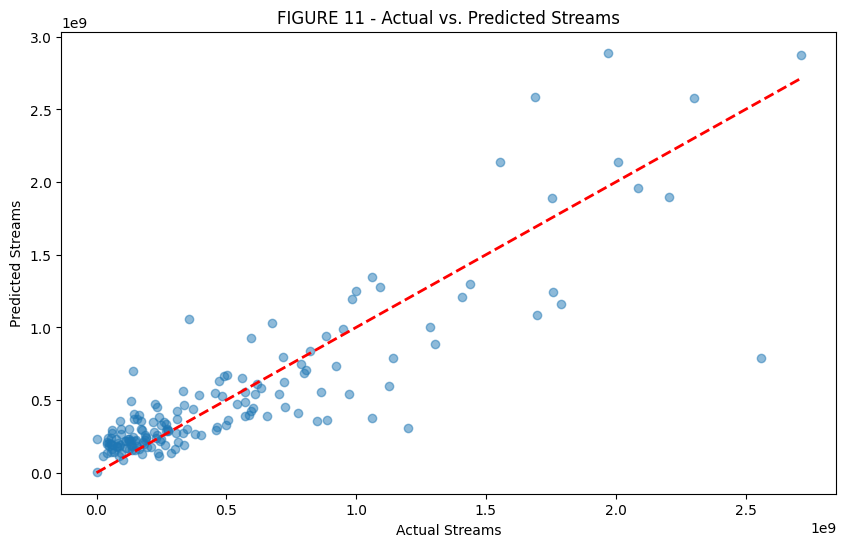

In [92]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Streams')
plt.ylabel('Predicted Streams')
plt.title('FIGURE 11 - Actual vs. Predicted Streams')
plt.show()

#### Understanding the Data
1. Compare MSE to the Target Variable's Range:

A key way to understand your MSE is to compare it to the range and variance of your target variable, 'streams'. A smaller MSE relative to the target's range is generally better.

Let's look at the descriptive statistics of the 'streams' column again to provide context for our MSE of approximately 7.81 x 10^16:

Mean: The average number of streams is about 469 million.
Standard Deviation: The standard deviation is about 523 million, which is very high and indicates a wide spread of data.
Min and Max: The number of streams ranges from about 2,762 to over 3.5 billion.

2. Root Mean Squared Error (RMSE):

To make the error more interpretable, we can take the square root of the MSE to get the Root Mean Squared Error (RMSE). The RMSE will be in the same units as our target variable (in this case, streams), which makes it easier to understand.

With RMSE we can see that our model's average prediction error is about 279 million streams. Given that the number of streams ranges from a few thousand to over 3.5 billion, and the standard deviation is over 500 million, an error of this magnitude, while large, is put into better perspective.

This concludes our analysis of the 2023 Spotify dataset and the creation of a predictive model. We have explored the data, identified key features, built and evaluated a linear regression model, and interpreted its results. *italicized text*

---
## Summary:

### Data Analysis Key Findings

*   The linear regression model trained on the top 10 most correlated features explained approximately 68% of the variance in the number of streams, as indicated by an R-squared score of 0.68.
*   The Mean Squared Error (MSE) of the model was approximately 7.86 x 10^16, which is very large, suggesting significant prediction errors.
*   Features like `artist_count`, `in_deezer_charts`, and `in_spotify_charts` had the largest absolute coefficients, indicating they have the most significant influence on the predicted stream count among the selected features.


## **DISCUSSION:**




1.  **Define which key features are most predictive of song popularity as identified by streams?**
    Using the correlation matrix and other analysis, presence in Spotify and Apple Playlists and Charts, as well as Release Year had the most predictive values.
2.  **Can we tell if music released during certain months influence streams(popularity)?**
    Based on the analysis, there appears to be a weak relationship between release month and streams, with summer months (June and July) potentially seeing higher average streams. The months November and December did not have higher than average streams compared to the rest of the year.
2a.  **Is energy, BPM, or liveliness related to particular release months, such as Christmas holidays (November through December)?**
    The analysis suggests that the relationship between release month (including the holiday season) and energy or liveliness appears to be negligible. Average energy and liveness show some fluctuations throughout the year, but the patterns are not as pronounced as those for streams, and the holiday season averages for energy and liveness were not significantly different from the overall averages.
3.  **Using the single most (intrinsic) predictive feature identified does this feature help predict popularity to the same degree if the 2024 Spotify data is also used?**
    Initially, used the predictive value of Release Year to train the model, but found the model required addiitional data points to increase accuracy. Unfortunately, intrinsic features were not terribly predictive of the stream number. The large MSE suggests that our model was not incredibly accurate, likely lacking specificity, as stated due to lack of comparable data points.

**Overall, my hypothesis was incorrect. Songs are not in fact streamed more during the designated months, November through December, and there was not an appreciable difference in elements such as BPM, liveness, or number of streams.**

### Next Steps
*   While a potential link between summer releases and higher streams was observed, further analysis incorporating factors like genre, artist popularity, and marketing could provide a more comprehensive understanding of stream trends.
*   Investigating specific holiday-themed music releases versus general releases during the holiday season might reveal more distinct patterns in energy and liveliness.
*   The high MSE suggests the linear regression model might not be the most suitable for predicting streams, potentially due to the non-linear relationships or outliers in the data. Exploring other regression models like tree-based models might improve performance.
*   Further investigation into the features with large coefficients, especially `artist_count`, `in_deezer_charts`, and `in_spotify_charts`, could provide insights into the key drivers of song popularity and streaming numbers.


---
### **Code and Data Availability**

The data has come from the 2023 and 2024 publicly available Spotify datasets
1. kagglehub.dataset_download("nelgiriyewithana/top-spotify-songs-2023")
2. kagglehub.dataset_download("nelgiriyewithana/most-streamed-spotify-songs-2024")

Github Repository
1. https://github.com/ERone1207/TCSRone/blob/main/EVAN_SPOTIFY_FINAL_Project_TCS_2025.ipynb


### **Acknowledgements**

*  The Coding School
*  Publicly available dataset: Spotify 2023 and 2024 Lists
*  **Durruya Alam (TA)**
*  Google for clarification and definitions
